In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "household_power_consumption.txt"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"

PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw dataset exists:", RAW_PATH.exists())

Project root: c:\projects\Electricity-Forecasting-AD
Raw dataset exists: True


In [13]:
df = pd.read_csv(
    RAW_PATH,
    sep=";",
    na_values=["?"],
    low_memory=False
)

numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.set_index("datetime").sort_index()

print("Shape:", df.shape)
print("Missing values:")
print(df.isna().sum())

Shape: (2075259, 7)
Missing values:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [14]:
missing_rows = df.isna().any(axis=1)

print("Rows with missing measurements:", missing_rows.sum())
print(
    "Percentage missing:",
    round(missing_rows.mean() * 100, 3),
    "%"
)

print("\nMissing values by column:")
print(df.isna().sum())

Rows with missing measurements: 25979
Percentage missing: 1.252 %

Missing values by column:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [15]:
df_15min = df.resample("15min").mean()

print("Original rows:", len(df))
print("Resampled rows:", len(df_15min))

display(df_15min.head())

Original rows: 2075259
Resampled rows: 138352


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:15:00,4.587333,0.484000,234.366667,19.700000,0.0,1.333333,16.833333
2006-12-16 17:30:00,4.140667,0.327733,234.768667,17.773333,0.0,0.733333,16.866667
2006-12-16 17:45:00,4.159333,0.028267,234.630000,17.786667,0.0,0.000000,16.866667
2006-12-16 18:00:00,4.121067,0.152533,235.566000,17.706667,0.0,19.933333,17.000000
2006-12-16 18:15:00,3.768533,0.017200,234.803333,16.226667,0.0,2.866667,16.933333


In [16]:
print("Missing values after resampling:")
print(df_15min.isna().sum())

print(
    "\nPercentage of incomplete intervals:",
    round(df_15min["Global_active_power"].isna().mean() * 100, 3),
    "%"
)

Missing values after resampling:
Global_active_power      1713
Global_reactive_power    1713
Voltage                  1713
Global_intensity         1713
Sub_metering_1           1713
Sub_metering_2           1713
Sub_metering_3           1713
dtype: int64

Percentage of incomplete intervals: 1.238 %


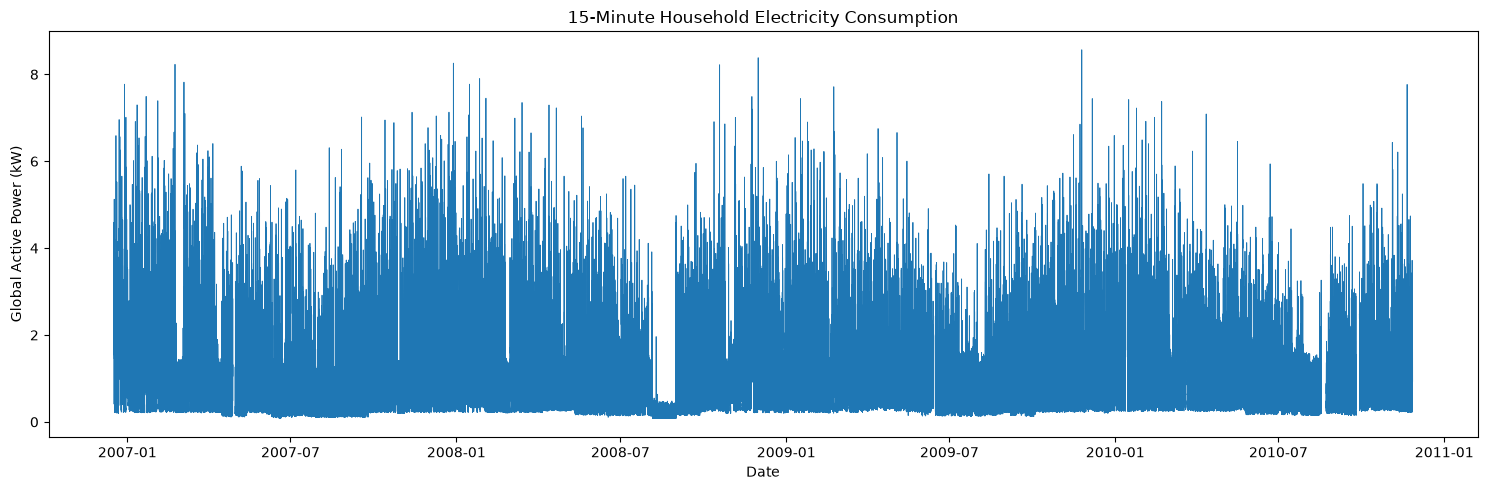

In [17]:
plt.figure(figsize=(15, 5))

plt.plot(
    df_15min.index,
    df_15min["Global_active_power"],
    linewidth=0.6
)

plt.title("15-Minute Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.tight_layout()
plt.show()

In [18]:
output_path = PROCESSED_PATH / "electricity_15min_intermediate.csv"

df_15min.to_csv(output_path)

print("Saved to:", output_path)

Saved to: c:\projects\Electricity-Forecasting-AD\data\processed\electricity_15min_intermediate.csv


In [19]:
# Count valid one-minute readings in each 15-minute interval

interval_counts = (
    df["Global_active_power"]
    .resample("15min")
    .count()
)

coverage_report = pd.DataFrame({
    "Valid Readings": interval_counts,
    "Missing Readings": 15 - interval_counts,
    "Coverage Percentage": (interval_counts / 15) * 100
})

print("Interval coverage distribution:")

display(
    coverage_report["Valid Readings"]
    .value_counts()
    .sort_index()
)

print("\nCoverage summary:")
display(coverage_report.describe())

Interval coverage distribution:


Valid Readings
0       1713
2          4
3          3
4          2
6          6
7          2
8          2
9          1
10         1
11         3
12         2
13        20
14        42
15    136551
Name: count, dtype: int64


Coverage summary:


,Valid Readings,Missing Readings,Coverage Percentage
count,138352.000000,138352.000000,138352.000000
mean,14.812074,0.187926,98.747157
std,1.663501,1.663501,11.090008
min,0.000000,0.000000,0.000000
25%,15.000000,0.000000,100.000000
50%,15.000000,0.000000,100.000000
75%,15.000000,0.000000,100.000000
max,15.000000,15.000000,100.000000


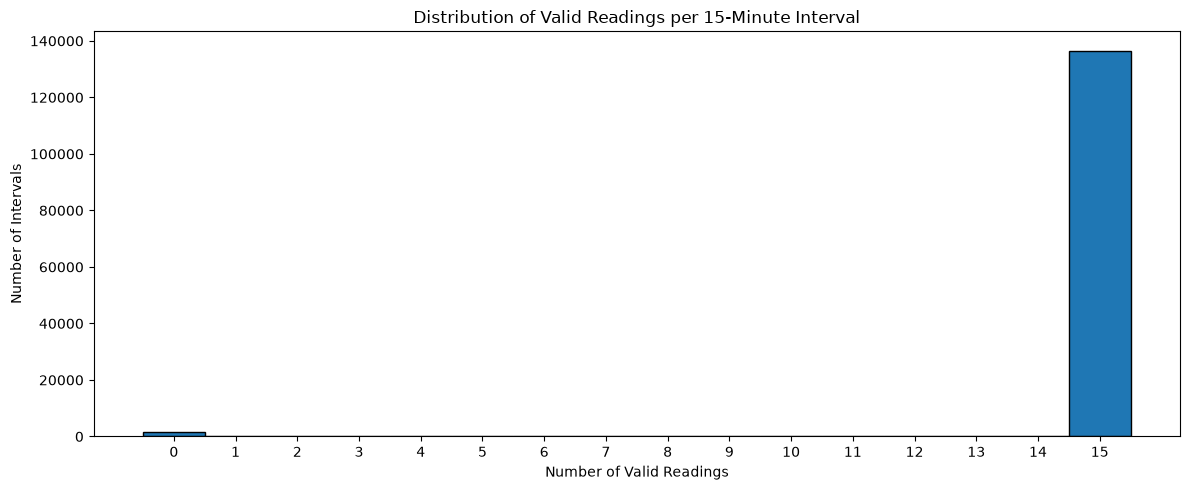

In [20]:
plt.figure(figsize=(12, 5))

plt.hist(
    interval_counts,
    bins=np.arange(-0.5, 16.5, 1),
    edgecolor="black"
)

plt.title("Distribution of Valid Readings per 15-Minute Interval")
plt.xlabel("Number of Valid Readings")
plt.ylabel("Number of Intervals")
plt.xticks(range(16))
plt.tight_layout()
plt.show()

In [21]:
# Identify intervals with zero valid readings

empty_intervals = interval_counts == 0

# Group consecutive empty intervals
gap_groups = (
    empty_intervals.ne(empty_intervals.shift())
    .cumsum()
)

gap_durations = (
    empty_intervals[empty_intervals]
    .groupby(gap_groups[empty_intervals])
    .size() * 15
)

print("Number of completely empty intervals:", empty_intervals.sum())

print("\nLongest missing periods (minutes):")
display(gap_durations.sort_values(ascending=False).head(10))

Number of completely empty intervals: 1713

Longest missing periods (minutes):


Global_active_power
28    7200
30    5220
2     3705
20    3300
24    3120
26    2010
22     885
6       60
14      45
8       30
Name: Global_active_power, dtype: int64

In [22]:
# Count valid active-power measurements in each interval

interval_counts = (
    df["Global_active_power"]
    .resample("15min")
    .count()
)

# Calculate coverage percentage
coverage = interval_counts / 15

# Display coverage distribution
print("Valid readings per interval:")
display(interval_counts.value_counts().sort_index())

print("\nCoverage statistics:")
display(coverage.describe())

Valid readings per interval:


Global_active_power
0       1713
2          4
3          3
4          2
6          6
7          2
8          2
9          1
10         1
11         3
12         2
13        20
14        42
15    136551
Name: count, dtype: int64


Coverage statistics:


count    138352.000000
mean          0.987472
std           0.110900
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: Global_active_power, dtype: float64

In [23]:
# Keep intervals with at least 80% valid readings

MIN_COVERAGE = 0.80

valid_intervals = coverage >= MIN_COVERAGE

# Filter the resampled dataset
df_clean = df_15min.loc[valid_intervals].copy()

print("Before cleaning:", len(df_15min))
print("After cleaning:", len(df_clean))
print("Removed intervals:", len(df_15min) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean.isna().sum())

Before cleaning: 138352
After cleaning: 136615
Removed intervals: 1737

Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [24]:
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isna().sum())

print("\nTime range:")
print("Start:", df_clean.index.min())
print("End:", df_clean.index.max())

print("\nTime intervals:")
display(df_clean.index.to_series().diff().value_counts().head(10))

Cleaned dataset shape: (136615, 7)

Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Time range:
Start: 2006-12-16 17:30:00
End: 2010-11-26 20:45:00

Time intervals:


datetime
0 days 00:15:00    136599
0 days 01:00:00         3
0 days 00:30:00         2
2 days 14:30:00         1
0 days 02:45:00         1
0 days 01:30:00         1
0 days 00:45:00         1
2 days 07:30:00         1
0 days 15:15:00         1
2 days 04:30:00         1
Name: count, dtype: int64

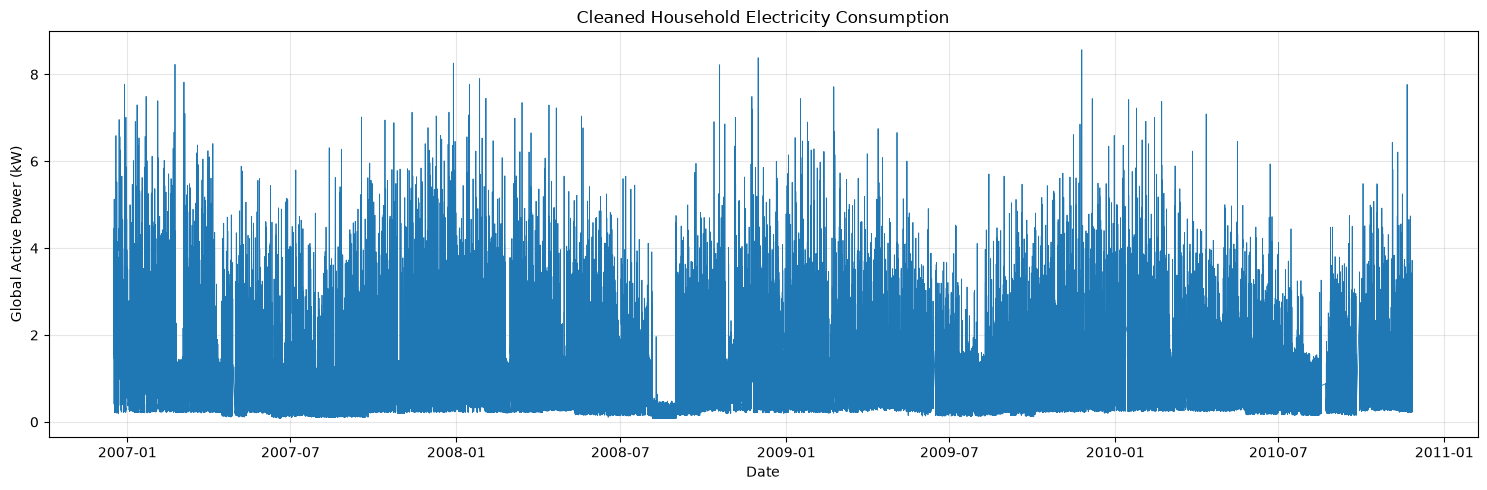

In [25]:
plt.figure(figsize=(15, 5))

plt.plot(
    df_clean.index,
    df_clean["Global_active_power"],
    linewidth=0.6
)

plt.title("Cleaned Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [26]:
CLEANED_PATH = (
    PROCESSED_PATH / "electricity_15min_cleaned.csv"
)

df_clean.to_csv(CLEANED_PATH)

print("Cleaned dataset saved successfully!")
print("Location:", CLEANED_PATH)

Cleaned dataset saved successfully!
Location: c:\projects\Electricity-Forecasting-AD\data\processed\electricity_15min_cleaned.csv


In [27]:
print("Cleaned shape:", df_clean.shape)
print("Start:", df_clean.index.min())
print("End:", df_clean.index.max())

Cleaned shape: (136615, 7)
Start: 2006-12-16 17:30:00
End: 2010-11-26 20:45:00


In [28]:
print(df_clean.isna().sum())

Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [29]:
time_gaps = df_clean.index.to_series().diff()

print("Normal 15-min intervals:", (time_gaps == pd.Timedelta("15min")).sum())
print("Unexpected gaps:", (time_gaps > pd.Timedelta("15min")).sum())
print("Largest gap:", time_gaps.max())

Normal 15-min intervals: 136599
Unexpected gaps: 15
Largest gap: 5 days 00:45:00


In [30]:
print(df_clean.isna().sum())
print("Total missing values:", df_clean.isna().sum().sum())

Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64
Total missing values: 0
